### Assignment-4 - Diabetes Prediction using KNN 

In [ ]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn import metrics



In [ ]:
df=pd.read_csv("diabetes.csv")
df.head()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,Pedigree,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
df.isnull().sum()

Pregnancies      0
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
Pedigree         0
Age              0
Outcome          0
dtype: int64

In [8]:
x=df.drop("Outcome",axis=1)
y=df["Outcome"]


In [9]:
X_train,X_test,y_train,y_test = train_test_split(x,y,test_size=0.3,random_state=42)
scaler=StandardScaler()

X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [10]:
knn=KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train,y_train)
pred=knn.predict(X_test)



In [15]:
print("Actual outcome",y_test.iloc[0])
print("Predicted outcome",pred[0])

Actual outcome 0
Predicted outcome 0


In [19]:
print("Accuracy",metrics.accuracy_score(y_test,pred))
print("Confusion Metrics",metrics.confusion_matrix(y_test,pred))
print("Precision",metrics.precision_score(y_test,pred))
print("MSE",metrics.mean_squared_error(y_test,pred))

Accuracy 0.7012987012987013
Confusion Metrics [[119  32]
 [ 37  43]]
Precision 0.5733333333333334
MSE 0.2987012987012987


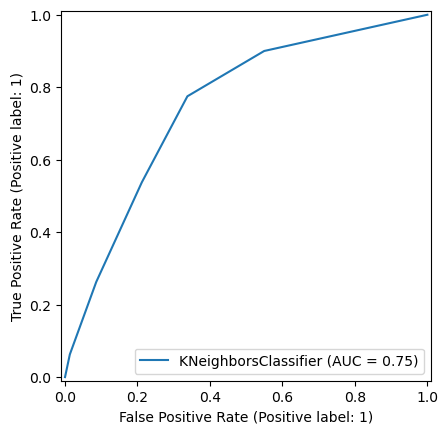

In [20]:
metrics.RocCurveDisplay.from_estimator(knn,X_test,y_test)
plt.show()

In [ ]:
y_prob=knn.predict_proba(X_test)[:,1]
print("Roc-Auc Curve",metrics.roc_auc_score(y_test,y_prob))
plt.show()

Roc-Auc Curver 0.7504552980132451
